Step 1 — Mount Google Drive and check the dataset folder

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Untitled form (1).gform', 'Untitled form.gform', '1000072592.jpg', 'VP_LAB3_ICT_22_884.zip', 'Screenshot 2024-08-05 233259.png', 'Colab Notebooks', '20241212_171645.jpg', 'SriLanka_Tour2.zip', '20250117_062443.jpg', 'WhatsApp Image 2025-02-11 at 7.41.46 PM.jpeg', 'IMG-20250611-WA0006.jpg', 'mood mirror', 'emotion-music-app-main.zip', 'Hostel form.pdf', 'Women’s Safety App Research Survey .gform', 'Asymmetric Encryption.gvid', 'M.N.F.Milfara_Software Technology (3).pdf', 'M.N.F.Milfara_Software Technology (2).pdf', 'M.N.F.Milfara_Software Technology (1).pdf', 'M.N.F.Milfara_Software Technology.pdf', 'M (2).N.F.Milfara.pdf', 'M (1).N.F.Milfara.pdf', 'M.N.F.Milfara.pdf', 'GWU BIPT 2020 39.xlsx', 'M.N.F.Milfara-ICT22884(Software Technology) (1).pdf', 'M.N.F.Milfara-ICT22884(Software Technology).pdf', 'Milfara-University of Sri Jayewardenepura (3).pdf', 'Milfara-University of Sri Jayewardenepura (2).pdf', 'Milfara-University of Sri Jayewardenepura (1).pdf', 'Milfara-University of Sri Jaye

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(dataset_path, split)

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            print(class_name, ":", len(os.listdir(class_path)))


TRAIN
Kaffir Lime : 210
Lemon : 210
Lime : 210
Orange : 210
Tangerine : 210

VALIDATION
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45

TEST
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45


Step 2 — Set up the background-removal filter

In [ ]:
!pip install "rembg[cpu]" onnxruntime

In [ ]:
from rembg import remove, new_session
from PIL import Image

rembg_session = new_session("u2net")

print("Background removal model loaded successfully.")

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

Background removal model loaded successfully.


Step 3 — Test background removal on one dataset image

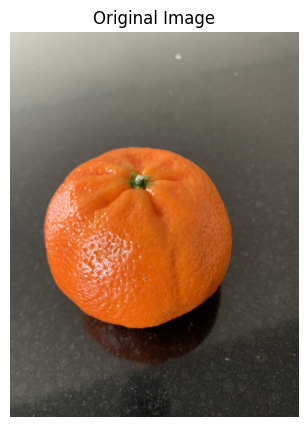

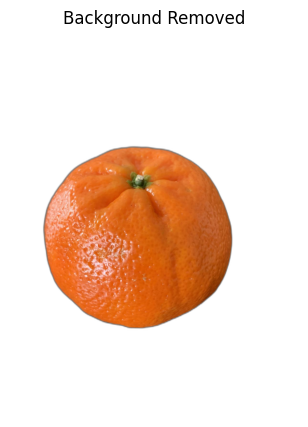

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
from rembg import remove

dataset_path = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"

# Choose one class to test
class_name = "Tangerine"

class_path = os.path.join(dataset_path, "train", class_name)

# Take the first image
image_name = os.listdir(class_path)[0]
image_path = os.path.join(class_path, image_name)

# Load image
input_image = Image.open(image_path).convert("RGB")

# Remove background
output_image = remove(
    input_image,
    session=rembg_session
)

# Show original
plt.figure(figsize=(5,5))
plt.imshow(input_image)
plt.axis("off")
plt.title("Original Image")
plt.show()

# Show background removed
plt.figure(figsize=(5,5))
plt.imshow(output_image)
plt.axis("off")
plt.title("Background Removed")
plt.show()

Step 4 — Create a separate background-removed dataset

In [ ]:
import os
from PIL import Image
from rembg import remove
from tqdm import tqdm

source_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"
output_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

splits = ["train", "validation", "test"]

for split in splits:

    source_split = os.path.join(source_dataset, split)
    output_split = os.path.join(output_dataset, split)

    for class_name in os.listdir(source_split):

        source_class = os.path.join(source_split, class_name)

        if not os.path.isdir(source_class):
            continue

        output_class = os.path.join(output_split, class_name)
        os.makedirs(output_class, exist_ok=True)

        print(f"\nProcessing {split} - {class_name}")

        for filename in tqdm(os.listdir(source_class)):

            source_path = os.path.join(source_class, filename)

            try:
                # Load original image
                img = Image.open(source_path).convert("RGB")

                # Remove background
                removed = remove(
                    img,
                    session=rembg_session
                ).convert("RGBA")

                # Create white background
                white_background = Image.new(
                    "RGBA",
                    removed.size,
                    (255, 255, 255, 255)
                )

                # Place fruit on white background
                final_img = Image.alpha_composite(
                    white_background,
                    removed
                ).convert("RGB")

                # Save as PNG
                file_stem = os.path.splitext(filename)[0]
                output_path = os.path.join(
                    output_class,
                    file_stem + ".png"
                )

                final_img.save(output_path)

            except Exception as e:
                print("Error:", source_path, e)

print("\nBackground removal completed!")


Processing train - Tangerine


  4%|▍         | 8/210 [00:25<10:32,  3.13s/it]


KeyboardInterrupt: 

In [ ]:
import os
from PIL import Image
from rembg import remove
from tqdm import tqdm

source_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"
output_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

splits = ["train", "validation", "test"]

for split in splits:

    source_split = os.path.join(source_dataset, split)

    for class_name in os.listdir(source_split):

        source_class = os.path.join(source_split, class_name)

        if not os.path.isdir(source_class):
            continue

        output_class = os.path.join(
            output_dataset,
            split,
            class_name
        )

        os.makedirs(output_class, exist_ok=True)

        print(f"\nProcessing {split} - {class_name}")

        for filename in tqdm(os.listdir(source_class)):

            source_path = os.path.join(source_class, filename)

            file_stem = os.path.splitext(filename)[0]

            output_path = os.path.join(
                output_class,
                file_stem + ".png"
            )

            # Skip images already processed
            if os.path.exists(output_path):
                continue

            try:
                print("Currently processing:", filename)

                img = Image.open(source_path).convert("RGB")

                removed = remove(
                    img,
                    session=rembg_session
                ).convert("RGBA")

                white_background = Image.new(
                    "RGBA",
                    removed.size,
                    (255, 255, 255, 255)
                )

                final_img = Image.alpha_composite(
                    white_background,
                    removed
                ).convert("RGB")

                final_img.save(output_path)

            except Exception as e:
                print("ERROR:", filename)
                print(e)

print("\nBackground removal completed!")


Processing train - Tangerine


100%|██████████| 210/210 [00:00<00:00, 3541.89it/s]



Processing train - Kaffir Lime


100%|██████████| 210/210 [00:00<00:00, 2347.75it/s]



Processing train - Orange


100%|██████████| 210/210 [00:00<00:00, 2698.54it/s]


... (21 outputs left out)


100%|██████████| 45/45 [00:00<00:00, 2584.75it/s]



Processing test - Lemon


100%|██████████| 45/45 [00:00<00:00, 2592.74it/s]


Background removal completed!


In [ ]:
import os

filtered_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(filtered_dataset, split)

    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len(os.listdir(class_path))
            total += count
            print(class_name, ":", count)

    print("Total:", total)


TRAIN
Kaffir Lime : 210
Lemon : 210
Lime : 210
Orange : 210
Tangerine : 210
Total: 1050

VALIDATION
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45
Total: 225

TEST
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45
Total: 225


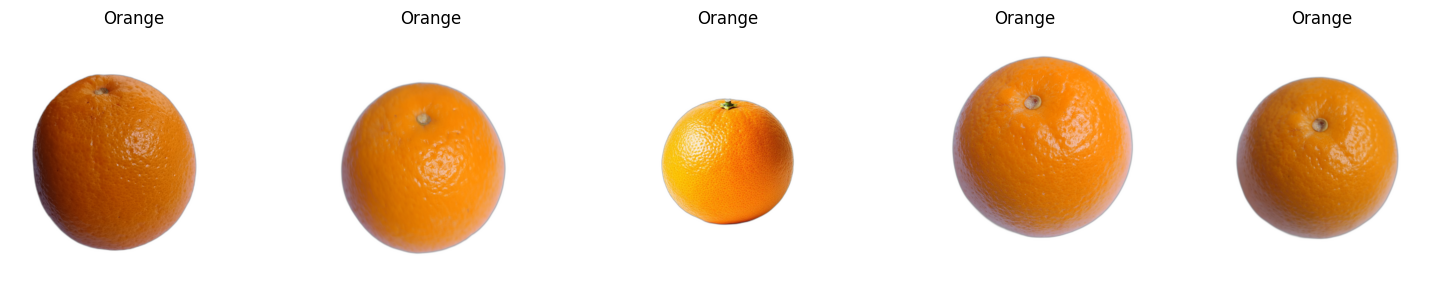

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

filtered_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

class_name = "Orange"
class_path = os.path.join(filtered_dataset, "train", class_name)

sample_images = random.sample(os.listdir(class_path), 5)

plt.figure(figsize=(15, 3))

for i, filename in enumerate(sample_images):
    img_path = os.path.join(class_path, filename)
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(class_name)

plt.tight_layout()
plt.show()

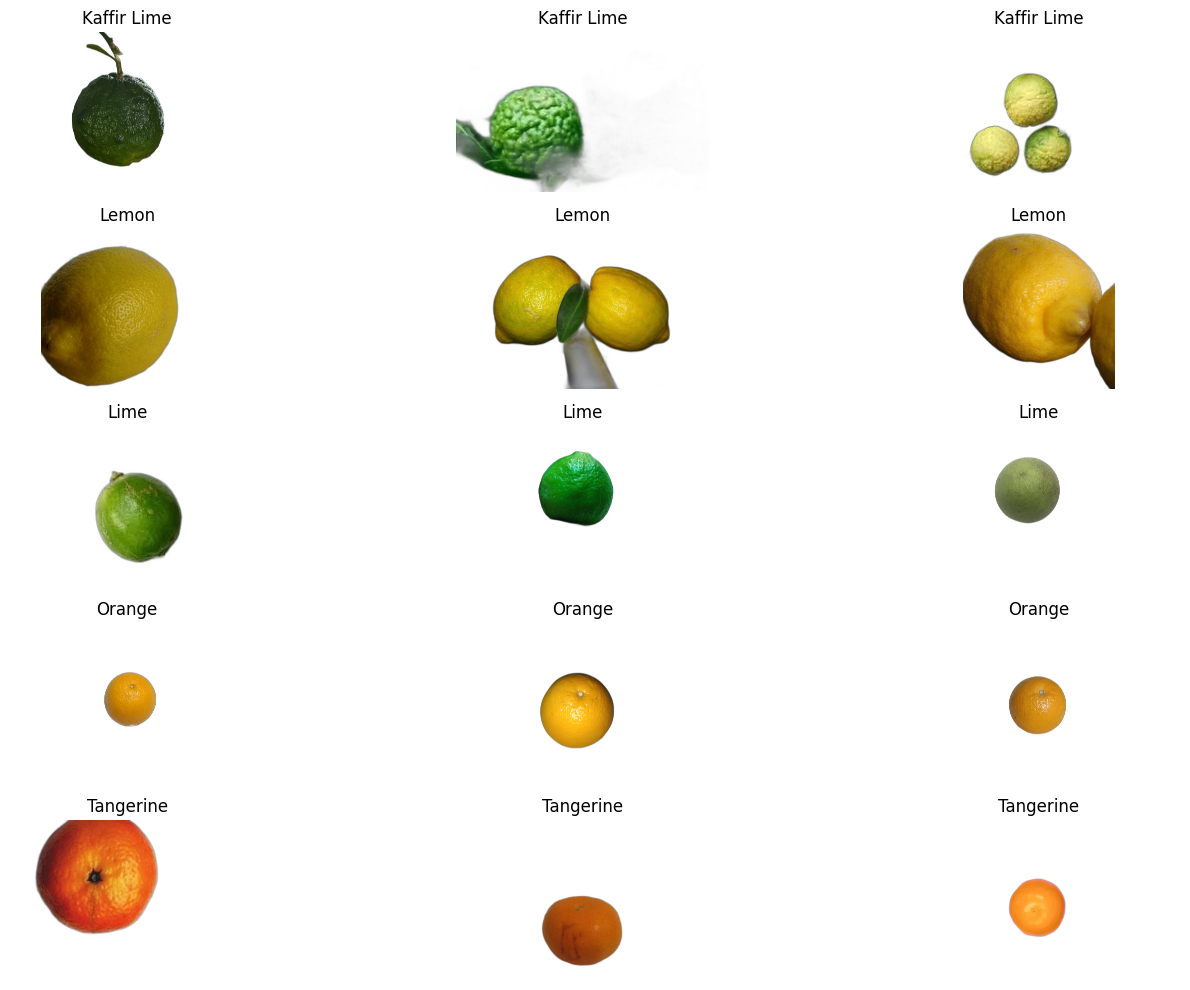

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

filtered_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

class_names = [
    "Kaffir Lime",
    "Lemon",
    "Lime",
    "Orange",
    "Tangerine"
]

plt.figure(figsize=(15, 10))

plot_index = 1

for class_name in class_names:
    class_path = os.path.join(
        filtered_dataset,
        "train",
        class_name
    )

    sample_images = random.sample(
        os.listdir(class_path),
        3
    )

    for filename in sample_images:
        img_path = os.path.join(class_path, filename)
        img = Image.open(img_path)

        plt.subplot(5, 3, plot_index)
        plt.imshow(img)
        plt.axis("off")
        plt.title(class_name)

        plot_index += 1

plt.tight_layout()
plt.show()

Load the filtered dataset into TensorFlow
(load the background-removed dataset and resize images to 224 × 224.)

In [ ]:
import tensorflow as tf
import os

dataset_path = "/content/drive/MyDrive/research dataset /Citrus_V2_Filtered_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = os.path.join(dataset_path, "train")
val_dir = os.path.join(dataset_path, "validation")
test_dir = os.path.join(dataset_path, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nClass names:", train_ds.class_names)

Found 1050 files belonging to 5 classes.
Found 225 files belonging to 5 classes.
Found 225 files belonging to 5 classes.

Class names: ['Kaffir Lime', 'Lemon', 'Lime', 'Orange', 'Tangerine']


Add data augmentation for training

In [ ]:
from tensorflow.keras import layers
from tensorflow.keras import Sequential

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="data_augmentation")

print("Data augmentation created successfully.")

Data augmentation created successfully.


Load MobileNetV2

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SHAPE = (224, 224, 3)

base_model = MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet"
)

# Freeze MobileNetV2 for the first training stage
base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Number of layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully.
Number of layers: 154


Build the complete classification model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

NUM_CLASSES = 5

inputs = tf.keras.Input(shape=(224, 224, 3))

# Training augmentation
x = data_augmentation(inputs)

# MobileNetV2 normalization
x = preprocess_input(x)

# Frozen MobileNetV2 feature extractor
x = base_model(x, training=False)

# Convert feature maps to one feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Final 5-class classifier
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile the model
(prepare the model for the first training stage.)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("V2 model compiled successfully.")

V2 model compiled successfully.


Training stage 1
(train only the new classification layer while MobileNetV2 remains frozen.)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/research dataset /citrus_v2_stage1_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history_v2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 226s 6s/step - accuracy: 0.6610 - loss: 0.9043 - val_accuracy: 0.7911 - val_loss: 0.5428
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 200s 6s/step - accuracy: 0.9162 - loss: 0.2857 - val_accuracy: 0.8178 - val_loss: 0.4588
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 202s 6s/step - accuracy: 0.9343 - loss: 0.2002 - val_accuracy: 0.8267 - val_loss: 0.4463
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 181s 5s/step - accuracy: 0.9514 - loss: 0.1661 - val_accuracy: 0.8311 - val_loss: 0.4441
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 232s 6s/step - accuracy: 0.9571 - loss: 0.1432 - val_accuracy: 0.8311 - val_loss: 0.4554
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 197s 6s/step - accuracy: 0.9629 - loss: 0.1320 - val_accuracy: 0.8311 - val_loss: 0.5149
Epoch 7/10
16/33 ━━━━━━━━━━━━━━━━━━━━ 1:25 5s/step - accuracy: 0.9789 - loss: 0.1053

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/research dataset /citrus_v2_stage1_best.keras"
)

print("Best Stage-1 model loaded.")

Best Stage-1 model loaded.


Evaluate the best Stage-1 model on validation data

In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", val_accuracy)
print("Validation Loss:", val_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 42s 4s/step - accuracy: 0.8311 - loss: 0.4441
Validation Accuracy: 0.8311111330986023
Validation Loss: 0.4441412389278412


Check validation predictions by class

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Predict validation dataset
val_predictions = model.predict(val_ds)

predicted_classes = np.argmax(val_predictions, axis=1)

# Actual validation labels
true_classes = np.concatenate([
    y.numpy() for x, y in val_ds
])

class_names = val_ds.class_names

print("Classification Report:\n")

print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=class_names,
        digits=4
    )
)

print("\nConfusion Matrix:")

cm_val = confusion_matrix(
    true_classes,
    predicted_classes
)

print(cm_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step
Classification Report:

              precision    recall  f1-score   support

 Kaffir Lime     0.9545    0.9333    0.9438        45
       Lemon     0.7377    1.0000    0.8491        45
        Lime     0.9348    0.9556    0.9451        45
      Orange     0.7241    0.4667    0.5676        45
   Tangerine     0.8000    0.8000    0.8000        45

    accuracy                         0.8311       225
   macro avg     0.8302    0.8311    0.8211       225
weighted avg     0.8302    0.8311    0.8211       225


Confusion Matrix:
[[42  0  3  0  0]
 [ 0 45  0  0  0]
 [ 1  1 43  0  0]
 [ 1 14  0 21  9]
 [ 0  1  0  8 36]]


show misclassified Orange validation images

Misclassified Orange images: 24


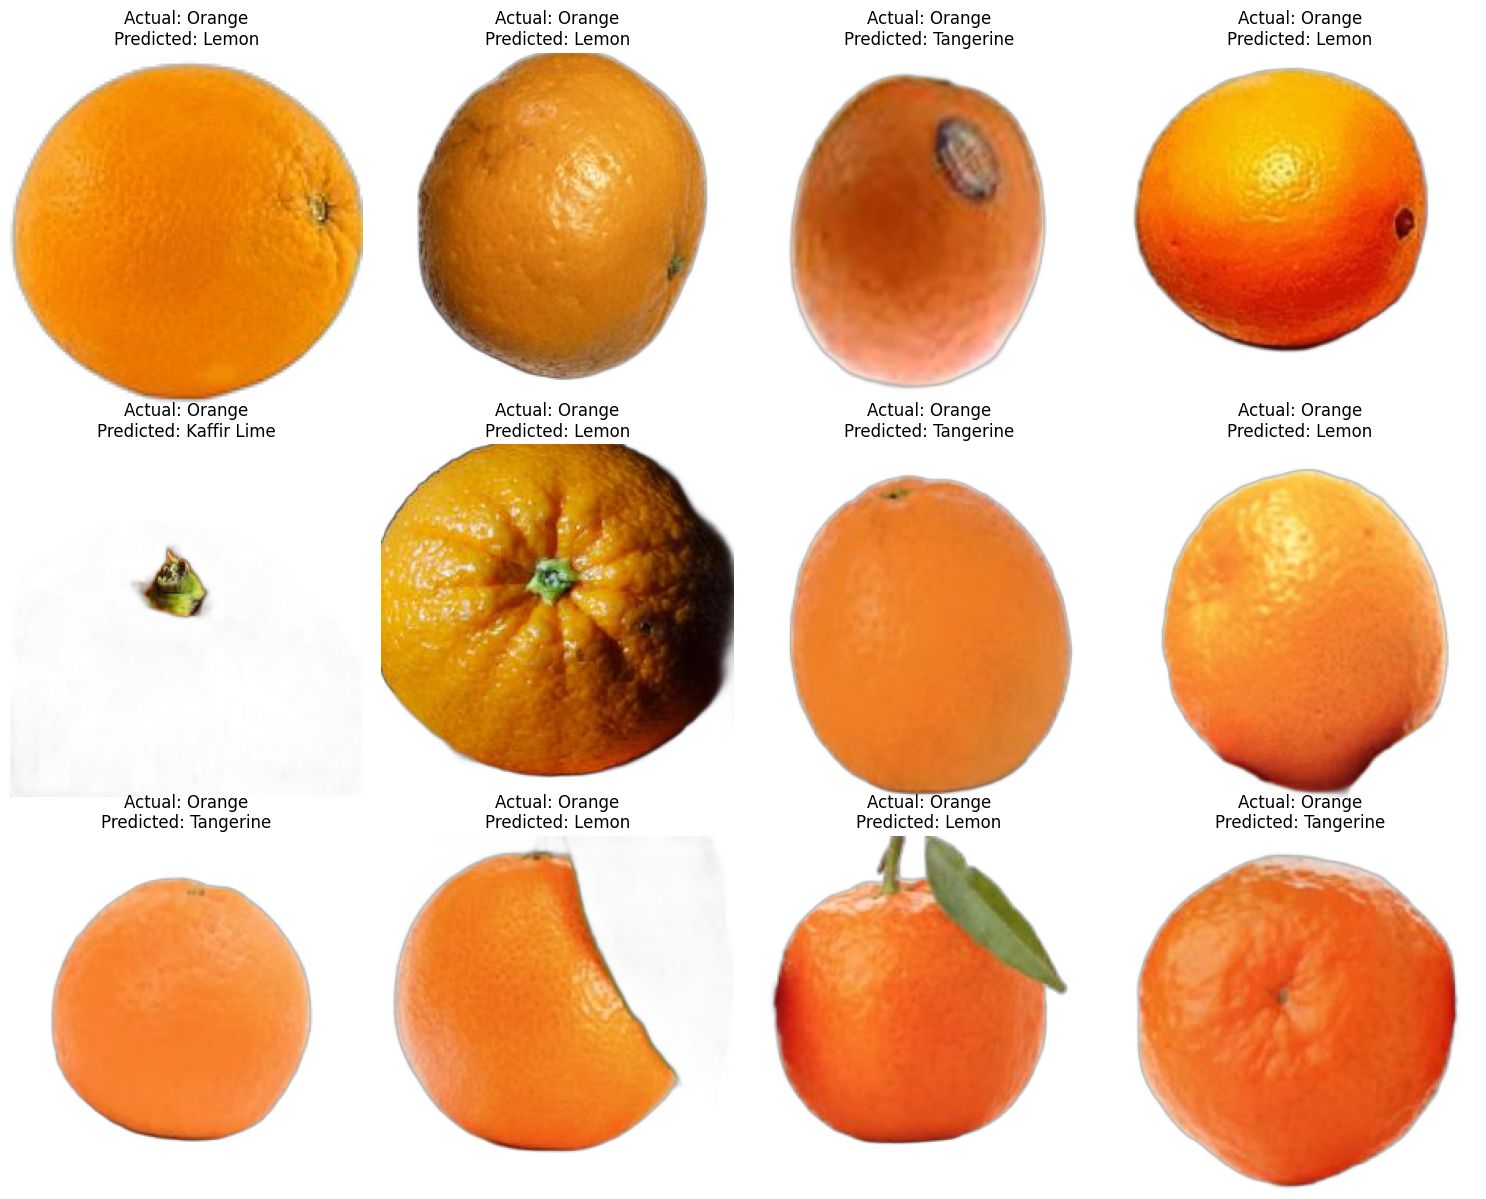

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

file_paths = val_ds.file_paths

orange_index = class_names.index("Orange")

wrong_orange_indices = [
    i for i in range(len(true_classes))
    if true_classes[i] == orange_index
    and predicted_classes[i] != orange_index
]

print("Misclassified Orange images:", len(wrong_orange_indices))

plt.figure(figsize=(15, 12))

for plot_num, idx in enumerate(wrong_orange_indices[:12]):

    img = Image.open(file_paths[idx])

    predicted_name = class_names[predicted_classes[idx]]

    plt.subplot(3, 4, plot_num + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Actual: Orange\nPredicted: {predicted_name}")

plt.tight_layout()
plt.show()

Resume Stage 1 Model Training

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/research dataset /citrus_v2_stage1_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history_continue = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=4,
    epochs=10,
    callbacks=callbacks
)

Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 234s 7s/step - accuracy: 0.9571 - loss: 0.1577 - val_accuracy: 0.8222 - val_loss: 0.4731
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 205s 6s/step - accuracy: 0.9619 - loss: 0.1367 - val_accuracy: 0.8178 - val_loss: 0.4948
Epoch 7/10
27/33 ━━━━━━━━━━━━━━━━━━━━ 35s 6s/step - accuracy: 0.9539 - loss: 0.1475

KeyboardInterrupt: 

**Test background blur on one original image** Pillow (PIL) Python library

In [ ]:
from rembg import new_session

rembg_session = new_session("u2net")

print("rembg session created successfully.")

rembg session created successfully.


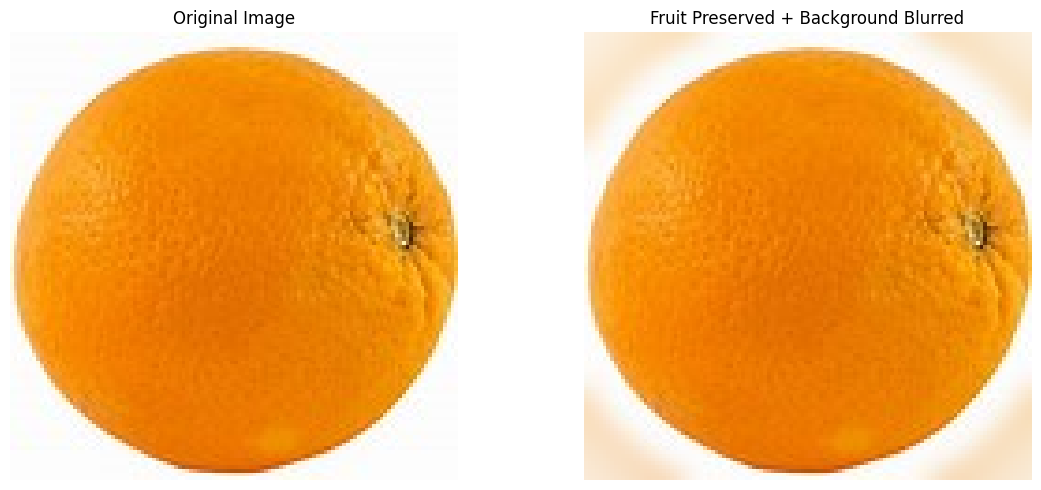

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from rembg import remove

original_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"

# Test one Orange validation image
class_path = os.path.join(
    original_dataset,
    "validation",
    "Orange"
)

image_name = os.listdir(class_path)[0]
image_path = os.path.join(class_path, image_name)

# Load original image
original = Image.open(image_path).convert("RGB")

# Get foreground mask
removed = remove(
    original,
    session=rembg_session
).convert("RGBA")

mask = removed.getchannel("A")

# Expand mask slightly to protect fruit edges
mask = mask.filter(ImageFilter.MaxFilter(15))

# Smooth mask edge
mask = mask.filter(ImageFilter.GaussianBlur(3))

# Blur only the background
blurred_background = original.filter(
    ImageFilter.GaussianBlur(20)
)

# Keep original fruit unchanged
final_image = Image.composite(
    original,
    blurred_background,
    mask
)

# Compare original and blurred-background image
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(final_image)
plt.axis("off")
plt.title("Fruit Preserved + Background Blurred")

plt.tight_layout()
plt.show()

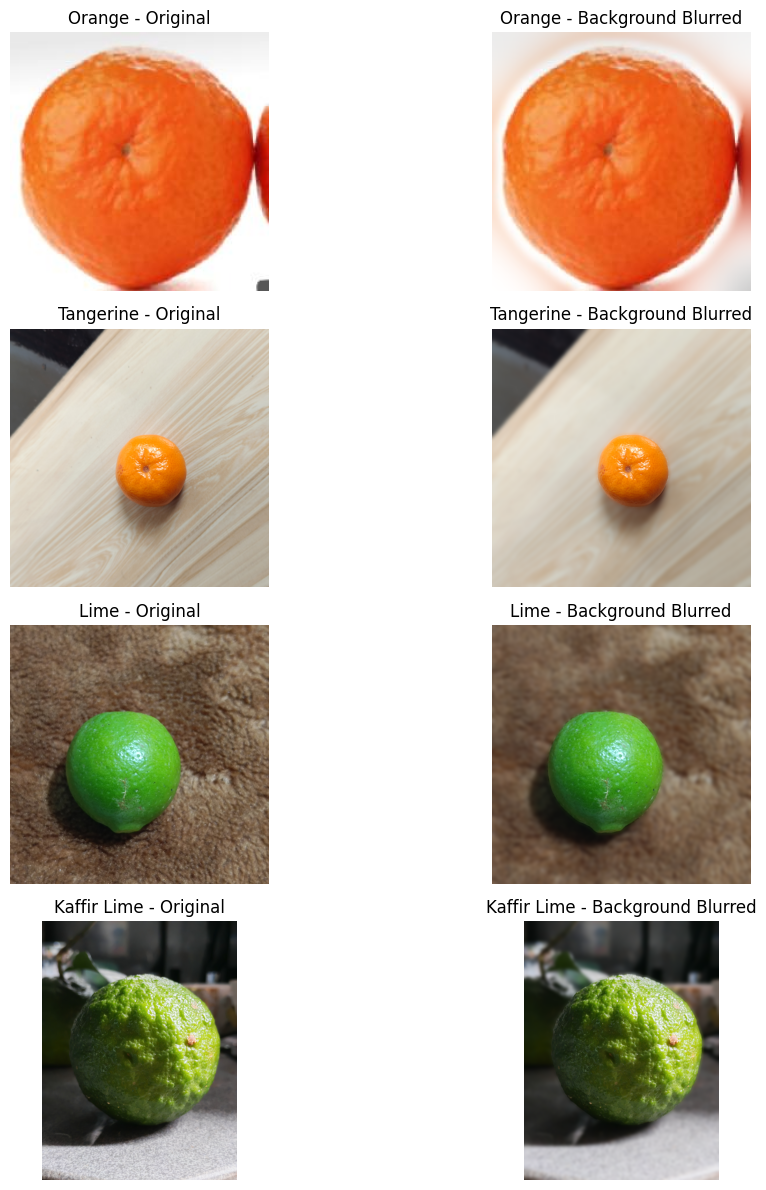

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from rembg import remove

original_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"

test_classes = [
    "Orange",
    "Tangerine",
    "Lime",
    "Kaffir Lime"
]

plt.figure(figsize=(12, 12))

plot_index = 1
for class_name in test_classes:

    class_path = os.path.join(
        original_dataset,
        "validation",
        class_name
    )

    sample_file = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, sample_file)

    original = Image.open(image_path).convert("RGB")

    # Get fruit mask
    removed = remove(
        original,
        session=rembg_session
    ).convert("RGBA")

    mask = removed.getchannel("A")

    # Protect fruit edges
    mask = mask.filter(ImageFilter.MaxFilter(15))
    mask = mask.filter(ImageFilter.GaussianBlur(3))

    # Blur background
    blurred_background = original.filter(
        ImageFilter.GaussianBlur(20)
    )

    final_image = Image.composite(
        original,
        blurred_background,
        mask
    )

    # Original
    plt.subplot(4, 2, plot_index)
    plt.imshow(original)
    plt.axis("off")
    plt.title(f"{class_name} - Original")
    plot_index += 1

    # Background blurred
    plt.subplot(4, 2, plot_index)
    plt.imshow(final_image)
    plt.axis("off")
    plt.title(f"{class_name} - Background Blurred")
    plot_index += 1

plt.tight_layout()
plt.show()

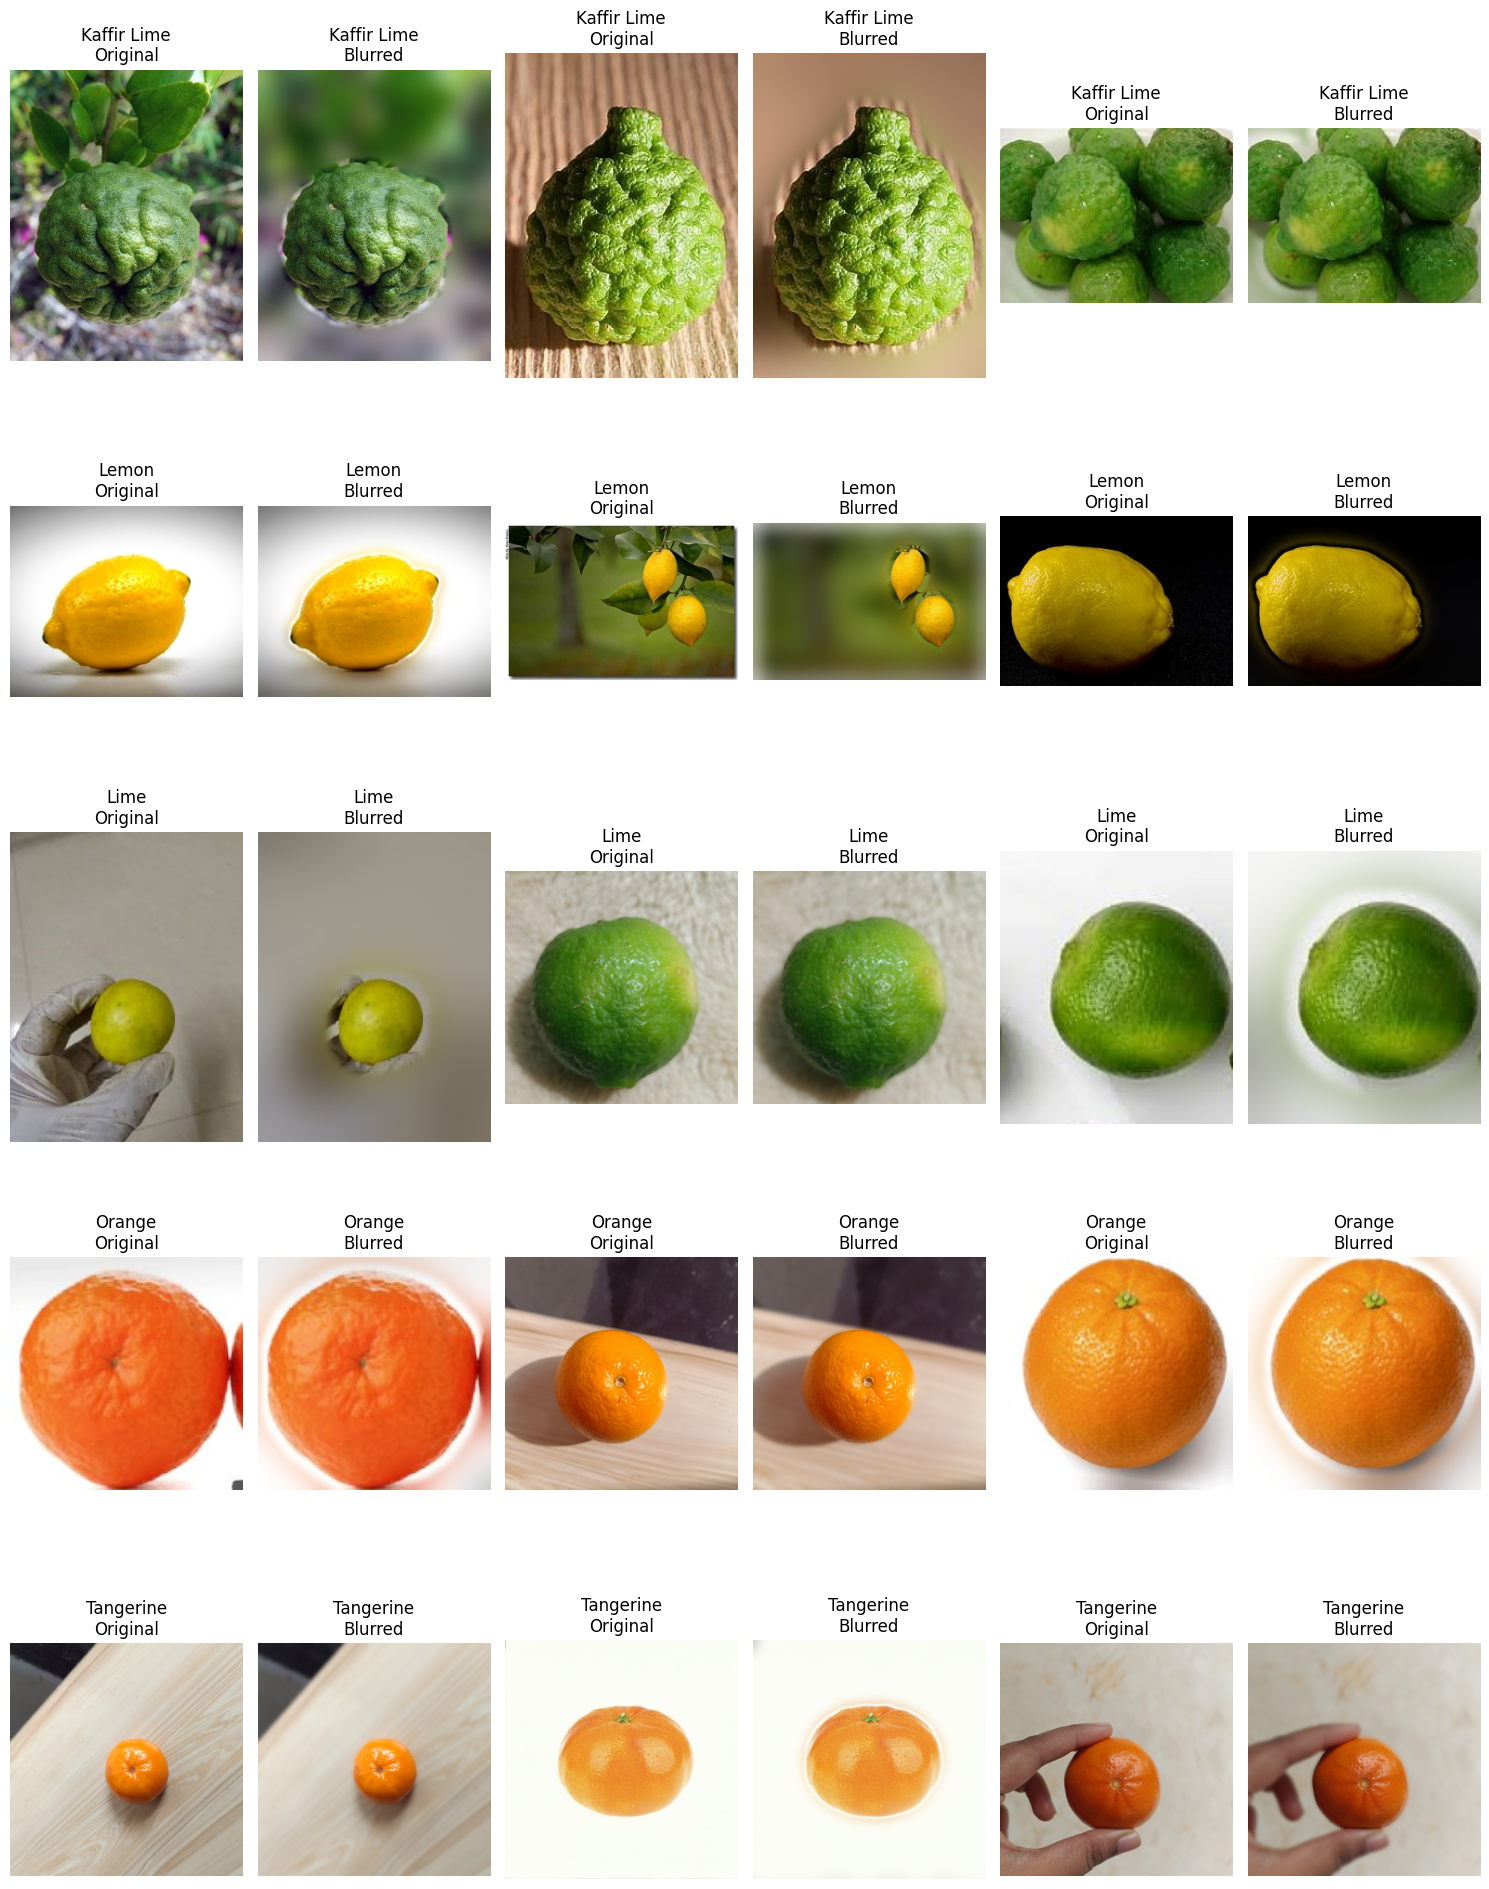

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from rembg import remove

original_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"

test_classes = [
    "Kaffir Lime",
    "Lemon",
    "Lime",
    "Orange",
    "Tangerine"
]

samples_per_class = 3

plt.figure(figsize=(15, 20))

plot_index = 1

for class_name in test_classes:

    class_path = os.path.join(
        original_dataset,
        "validation",
        class_name
    )

    sample_files = random.sample(
        os.listdir(class_path),
        samples_per_class
    )

    for sample_file in sample_files:

        image_path = os.path.join(class_path, sample_file)

        original = Image.open(image_path).convert("RGB")

        removed = remove(
            original,
            session=rembg_session
        ).convert("RGBA")

        mask = removed.getchannel("A")

        # Protect fruit edges
        mask = mask.filter(ImageFilter.MaxFilter(15))
        mask = mask.filter(ImageFilter.GaussianBlur(3))

        # Blur only the background
        blurred_background = original.filter(
            ImageFilter.GaussianBlur(20)
        )

        final_image = Image.composite(
            original,
            blurred_background,
            mask
        )

        # Original
        plt.subplot(5, 6, plot_index)
        plt.imshow(original)
        plt.axis("off")
        plt.title(f"{class_name}\nOriginal")
        plot_index += 1

        # Background blurred
        plt.subplot(5, 6, plot_index)
        plt.imshow(final_image)
        plt.axis("off")
        plt.title(f"{class_name}\nBlurred")
        plot_index += 1

plt.tight_layout()
plt.show()

Create the full blurred-background dataset

In [ ]:
import os
from PIL import Image, ImageFilter
from rembg import remove
from tqdm import tqdm

source_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"
output_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Blurred_Dataset"

splits = ["train", "validation", "test"]

for split in splits:

    source_split = os.path.join(source_dataset, split)

    for class_name in os.listdir(source_split):

        source_class = os.path.join(source_split, class_name)

        if not os.path.isdir(source_class):
            continue

        output_class = os.path.join(
            output_dataset,
            split,
            class_name
        )

        os.makedirs(output_class, exist_ok=True)

        print(f"\nProcessing {split} - {class_name}")

        for filename in tqdm(os.listdir(source_class)):

            source_path = os.path.join(source_class, filename)

            file_stem = os.path.splitext(filename)[0]
            output_path = os.path.join(
                output_class,
                file_stem + ".png"
            )

            # Skip if already processed
            if os.path.exists(output_path):
                continue

            try:
                # Load original image
                original = Image.open(source_path).convert("RGB")

                # Generate foreground mask
                removed = remove(
                    original,
                    session=rembg_session
                ).convert("RGBA")

                mask = removed.getchannel("A")

                # Protect fruit edges
                mask = mask.filter(
                    ImageFilter.MaxFilter(15)
                )

                mask = mask.filter(
                    ImageFilter.GaussianBlur(3)
                )

                # Blur only background
                blurred_background = original.filter(
                    ImageFilter.GaussianBlur(20)
                )

                # Keep original fruit sharp
                final_image = Image.composite(
                    original,
                    blurred_background,
                    mask
                )

                final_image.save(output_path)

            except Exception as e:
                print("ERROR:", filename)
                print(e)

print("\nBlurred-background dataset completed!")


Processing train - Tangerine


100%|██████████| 210/210 [49:28<00:00, 14.14s/it]



Processing train - Kaffir Lime


100%|██████████| 210/210 [21:42<00:00,  6.20s/it]



Processing train - Orange


 19%|█▊        | 39/210 [09:36<41:33, 14.58s/it]

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
!pip install "rembg[cpu]" onnxruntime

In [2]:
from rembg import new_session

rembg_session = new_session("u2net")

print("Background processing session ready.")

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

Background processing session ready.


Resume the blurred-background dataset processing
Run the same processing cell again:

In [3]:
import os
from PIL import Image, ImageFilter
from rembg import remove
from tqdm import tqdm

source_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"
output_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Blurred_Dataset"

splits = ["train", "validation", "test"]

for split in splits:

    source_split = os.path.join(source_dataset, split)

    for class_name in os.listdir(source_split):

        source_class = os.path.join(source_split, class_name)

        if not os.path.isdir(source_class):
            continue

        output_class = os.path.join(
            output_dataset,
            split,
            class_name
        )

        os.makedirs(output_class, exist_ok=True)

        print(f"\nProcessing {split} - {class_name}")

        for filename in tqdm(os.listdir(source_class)):

            source_path = os.path.join(source_class, filename)

            file_stem = os.path.splitext(filename)[0]

            output_path = os.path.join(
                output_class,
                file_stem + ".png"
            )

            # Skip images already processed
            if os.path.exists(output_path):
                continue

            try:
                original = Image.open(source_path).convert("RGB")

                removed = remove(
                    original,
                    session=rembg_session
                ).convert("RGBA")

                mask = removed.getchannel("A")

                mask = mask.filter(
                    ImageFilter.MaxFilter(15)
                )

                mask = mask.filter(
                    ImageFilter.GaussianBlur(3)
                )

                blurred_background = original.filter(
                    ImageFilter.GaussianBlur(20)
                )

                final_image = Image.composite(
                    original,
                    blurred_background,
                    mask
                )

                final_image.save(output_path)

            except Exception as e:
                print("ERROR:", filename)
                print(e)

print("\nBlurred-background dataset completed!")


Processing train - Tangerine


100%|██████████| 210/210 [00:00<00:00, 237.74it/s]



Processing train - Kaffir Lime


100%|██████████| 210/210 [00:00<00:00, 2839.52it/s]



Processing train - Orange


100%|██████████| 210/210 [00:00<00:00, 2962.44it/s]


... (19 outputs left out)

  8%|▊         | 16/210 [02:25<39:26, 12.20s/it]

ERROR: Li26.jpg
images do not match


  8%|▊         | 16/210 [02:38<31:58,  9.89s/it]


KeyboardInterrupt: 

In [4]:
from PIL import ImageOps

In [5]:
from PIL import Image, ImageFilter, ImageOps
from rembg import remove
import os

source_path = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)/train/Lime/Li13.jpg"

# Load image and fix EXIF orientation
original = Image.open(source_path).convert("RGB")
original = ImageOps.exif_transpose(original)

# Create foreground mask
removed = remove(
    original,
    session=rembg_session
).convert("RGBA")

mask = removed.getchannel("A")

print("Original size:", original.size)
print("Mask size:", mask.size)

# Fix size if needed
if mask.size != original.size:
    mask = mask.resize(
        original.size,
        Image.Resampling.LANCZOS
    )

print("Final mask size:", mask.size)

Original size: (2874, 3831)
Mask size: (2874, 3831)
Final mask size: (2874, 3831)


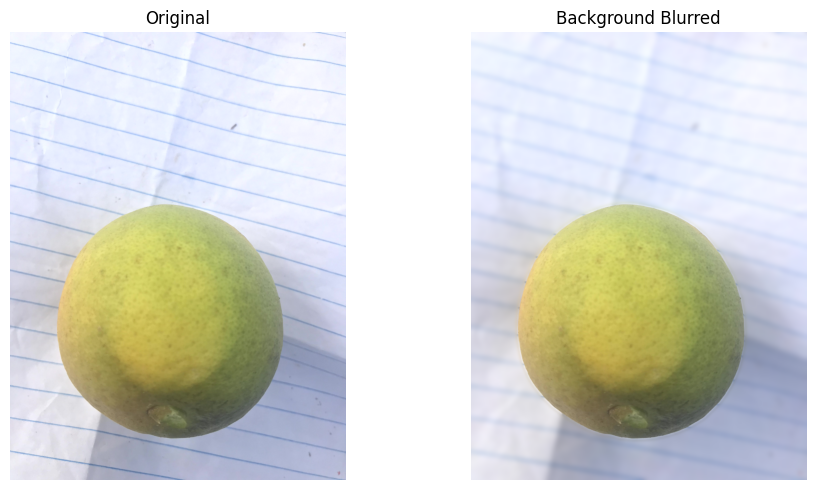

Li13 processed successfully.


In [6]:
import matplotlib.pyplot as plt
from PIL import ImageFilter

# Protect fruit edges
mask_fixed = mask.filter(
    ImageFilter.MaxFilter(15)
)

mask_fixed = mask_fixed.filter(
    ImageFilter.GaussianBlur(3)
)

# Blur the background
blurred_background = original.filter(
    ImageFilter.GaussianBlur(20)
)

# Combine sharp fruit + blurred background
final_image = Image.composite(
    original,
    blurred_background,
    mask_fixed
)

# Show result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.axis("off")
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(final_image)
plt.axis("off")
plt.title("Background Blurred")

plt.tight_layout()
plt.show()

print("Li13 processed successfully.")

 Resume the full dataset with the safer image handling

In [7]:
import os
from PIL import Image, ImageFilter, ImageOps
from rembg import remove
from tqdm import tqdm

source_dataset = "/content/drive/MyDrive/research dataset /Citrus_Split_Dataset(1)"
output_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Blurred_Dataset"

splits = ["train", "validation", "test"]

for split in splits:

    source_split = os.path.join(source_dataset, split)

    for class_name in os.listdir(source_split):

        source_class = os.path.join(source_split, class_name)

        if not os.path.isdir(source_class):
            continue

        output_class = os.path.join(
            output_dataset,
            split,
            class_name
        )

        os.makedirs(output_class, exist_ok=True)

        print(f"\nProcessing {split} - {class_name}")

        for filename in tqdm(os.listdir(source_class)):

            source_path = os.path.join(source_class, filename)

            file_stem = os.path.splitext(filename)[0]

            output_path = os.path.join(
                output_class,
                file_stem + ".png"
            )

            # Skip images already completed
            if os.path.exists(output_path):
                continue

            try:
                # Load image and correct orientation
                original = Image.open(source_path)
                original = ImageOps.exif_transpose(original)
                original = original.convert("RGB")

                # Create fruit mask
                removed = remove(
                    original,
                    session=rembg_session
                ).convert("RGBA")

                mask = removed.getchannel("A")

                # Make sure mask and image sizes match
                if mask.size != original.size:
                    mask = mask.resize(
                        original.size,
                        Image.Resampling.LANCZOS
                    )

                # Protect fruit edges
                mask = mask.filter(
                    ImageFilter.MaxFilter(15)
                )

                mask = mask.filter(
                    ImageFilter.GaussianBlur(3)
                )

                # Blur background
                blurred_background = original.filter(
                    ImageFilter.GaussianBlur(20)
                )

                # Keep fruit sharp
                final_image = Image.composite(
                    original,
                    blurred_background,
                    mask
                )

                final_image.save(output_path)

            except Exception as e:
                print("\nERROR:", filename)
                print(e)

print("\nBlurred-background dataset completed!")


Processing train - Tangerine


100%|██████████| 210/210 [00:00<00:00, 927.53it/s] 



Processing train - Kaffir Lime


100%|██████████| 210/210 [00:00<00:00, 1063.01it/s]



Processing train - Orange


100%|██████████| 210/210 [00:00<00:00, 1798.95it/s]


... (21 outputs left out)

100%|██████████| 45/45 [09:36<00:00, 12.82s/it]



Processing test - Lemon


100%|██████████| 45/45 [02:24<00:00,  3.20s/it]


Blurred-background dataset completed!


The problem did not happen earlier because those images had compatible orientation and dimensions. Some later images have different image metadata or encoding, so we added extra preprocessing to standardize them before blurring.

Verify the blurred dataset counts

In [8]:
import os

blurred_dataset = "/content/drive/MyDrive/research dataset /Citrus_V2_Blurred_Dataset"

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(blurred_dataset, split)
    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len(os.listdir(class_path))
            total += count
            print(class_name, ":", count)

    print("Total:", total)


TRAIN
Kaffir Lime : 210
Lemon : 210
Lime : 210
Orange : 210
Tangerine : 210
Total: 1050

VALIDATION
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45
Total: 225

TEST
Kaffir Lime : 45
Lemon : 45
Lime : 45
Orange : 45
Tangerine : 45
Total: 225


Load the blurred dataset into TensorFlow

In [9]:
import tensorflow as tf

dataset_path = "/content/drive/MyDrive/research dataset /Citrus_V2_Blurred_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)

Found 1050 files belonging to 5 classes.
Found 225 files belonging to 5 classes.
Found 225 files belonging to 5 classes.
Classes: ['Kaffir Lime', 'Lemon', 'Lime', 'Orange', 'Tangerine']


Create the training data augmentation

In [10]:
from tensorflow.keras import Sequential
from tensorflow.keras import layers

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="data_augmentation")

print("Data augmentation ready.")

Data augmentation ready.


Load a fresh MobileNetV2 base model

In [11]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded.")
print("Number of layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded.
Number of layers: 154


Build the V2 classification model

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    5,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile the model

In [13]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


Start Stage 1 training

In [14]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/research dataset /citrus_v2_blur_stage1_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 353s 10s/step - accuracy: 0.6800 - loss: 0.8665 - val_accuracy: 0.7556 - val_loss: 0.6151
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 215s 7s/step - accuracy: 0.9200 - loss: 0.2720 - val_accuracy: 0.7867 - val_loss: 0.5381
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 270s 7s/step - accuracy: 0.9352 - loss: 0.1941 - val_accuracy: 0.8000 - val_loss: 0.4980
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 266s 7s/step - accuracy: 0.9552 - loss: 0.1534 - val_accuracy: 0.8133 - val_loss: 0.4763
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 245s 6s/step - accuracy: 0.9667 - loss: 0.1235 - val_accuracy: 0.8089 - val_loss: 0.4914
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 282s 7s/step - accuracy: 0.9657 - loss: 0.1167 - val_accuracy: 0.8133 - val_loss: 0.4684
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 257s 7s/step - accuracy: 0.9695 - loss: 0.1036 - val_accuracy: 0.8000 - val_loss: 0.4898
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 259s 7s/step - accuracy: 0.9724 - loss: 0.0882 - val_accuracy: 0.8044 - 

confirm the restored validation result

In [15]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", val_accuracy)
print("Validation Loss:", val_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.8133 - loss: 0.4684
Validation Accuracy: 0.8133333325386047
Validation Loss: 0.46838733553886414


Validation classification report

In [16]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

print("Confusion Matrix:\n")
print(confusion_matrix(y_true, y_pred))

Classification Report:

              precision    recall  f1-score   support

 Kaffir Lime     0.9348    0.9556    0.9451        45
       Lemon     0.8367    0.9111    0.8723        45
        Lime     0.9362    0.9778    0.9565        45
      Orange     0.6774    0.4667    0.5526        45
   Tangerine     0.6538    0.7556    0.7010        45

    accuracy                         0.8133       225
   macro avg     0.8078    0.8133    0.8055       225
weighted avg     0.8078    0.8133    0.8055       225

Confusion Matrix:

[[43  0  2  0  0]
 [ 1 41  1  2  0]
 [ 1  0 44  0  0]
 [ 1  5  0 21 18]
 [ 0  3  0  8 34]]


Show misclassified validation images

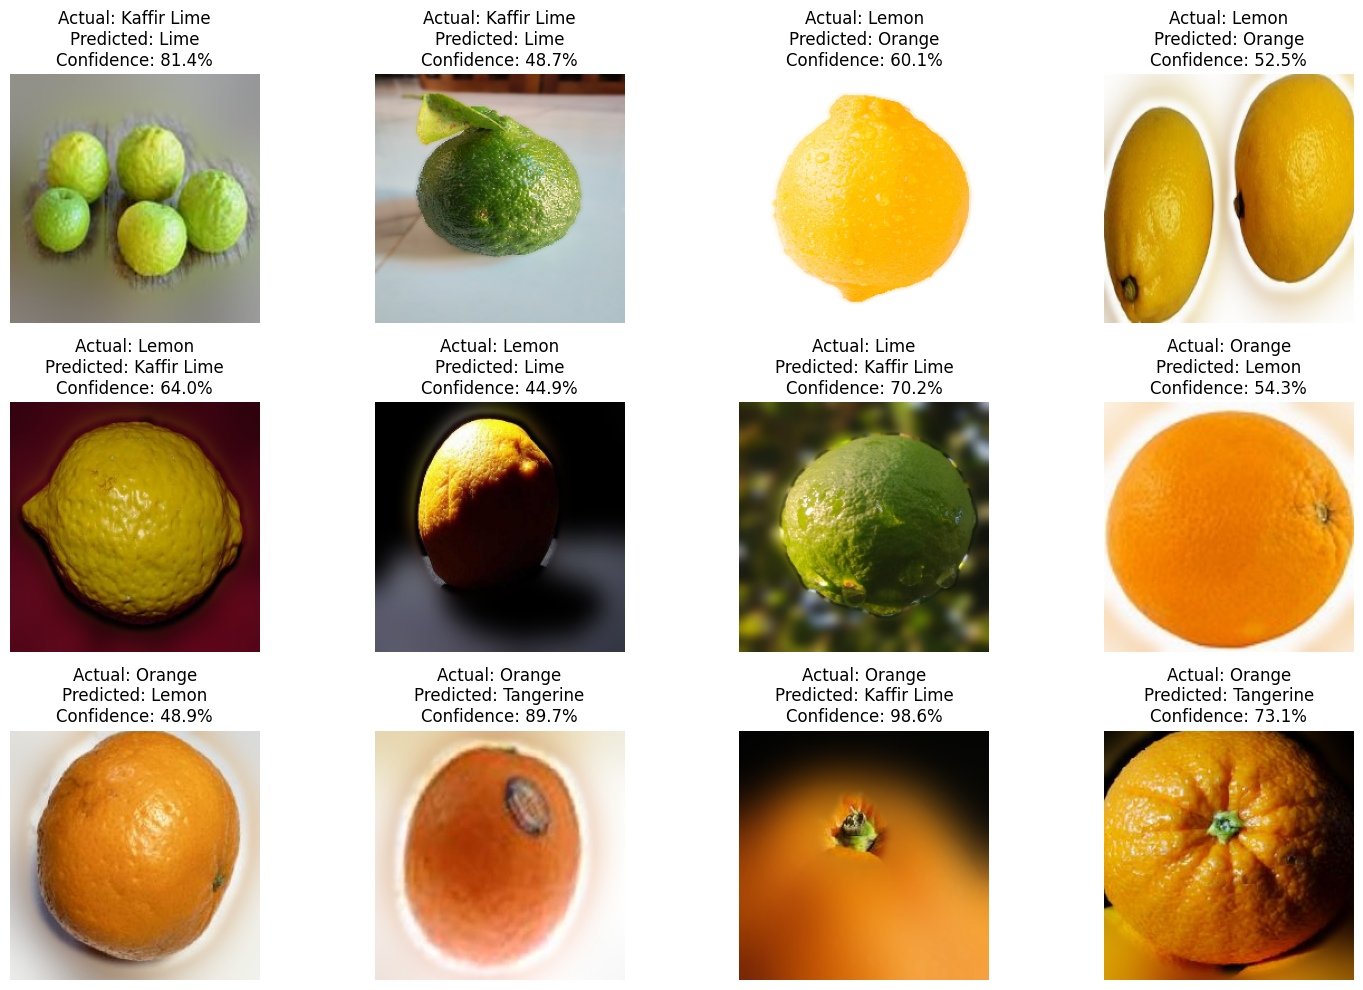

Total misclassified images: 42


In [17]:
import matplotlib.pyplot as plt
import numpy as np

misclassified_images = []
actual_labels = []
predicted_labels = []
confidences = []

for images, labels in val_ds:

    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    predicted_confidences = np.max(predictions, axis=1)

    for i in range(len(labels)):

        actual = labels[i].numpy()
        predicted = predicted_classes[i]

        if actual != predicted:
            misclassified_images.append(images[i].numpy().astype("uint8"))
            actual_labels.append(class_names[actual])
            predicted_labels.append(class_names[predicted])
            confidences.append(predicted_confidences[i])

# Show first 12 wrong predictions
num_images = min(12, len(misclassified_images))

plt.figure(figsize=(15, 10))

for i in range(num_images):

    plt.subplot(3, 4, i + 1)

    plt.imshow(misclassified_images[i])

    plt.title(
        f"Actual: {actual_labels[i]}\n"
        f"Predicted: {predicted_labels[i]}\n"
        f"Confidence: {confidences[i]*100:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total misclassified images:", len(misclassified_images))


prepare mobilenetv2 for fine tuning

In [19]:
base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total MobileNetV2 layers:", len(base_model.layers))
print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 13


Compile for fine-tuning

In [20]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully.")

Fine-tuning model compiled successfully.


Start fine-tuning

In [21]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

fine_tune_checkpoint = "/content/drive/MyDrive/research dataset /citrus_v2_blur_finetuned_best.keras"

fine_tune_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        fine_tune_checkpoint,
        monitor="val_loss",
        save_best_only=True
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 264s 8s/step - accuracy: 0.9714 - loss: 0.0977 - val_accuracy: 0.8044 - val_loss: 0.5640
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 246s 7s/step - accuracy: 0.9695 - loss: 0.0848 - val_accuracy: 0.8267 - val_loss: 0.5106
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 259s 7s/step - accuracy: 0.9752 - loss: 0.0707 - val_accuracy: 0.8356 - val_loss: 0.4784
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 276s 8s/step - accuracy: 0.9838 - loss: 0.0575 - val_accuracy: 0.8400 - val_loss: 0.4784
Epoch 5/10
31/33 ━━━━━━━━━━━━━━━━━━━━ 11s 6s/step - accuracy: 0.9750 - loss: 0.0634

KeyboardInterrupt: 

due to manual interaption

In [22]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/research dataset /citrus_v2_blur_finetuned_best.keras"
)

print("Best fine-tuned model loaded.")

Best fine-tuned model loaded.


In [23]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Fine-tuned Validation Accuracy:", val_accuracy)
print("Fine-tuned Validation Loss:", val_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.8400 - loss: 0.4784
Fine-tuned Validation Accuracy: 0.8399999737739563
Fine-tuned Validation Loss: 0.4784184396266937


Continue fine-tuning

In [24]:
history_fine_continue = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=4,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 247s 7s/step - accuracy: 0.9790 - loss: 0.0570 - val_accuracy: 0.8356 - val_loss: 0.5778
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 235s 7s/step - accuracy: 0.9876 - loss: 0.0423 - val_accuracy: 0.8489 - val_loss: 0.4740
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 263s 7s/step - accuracy: 0.9829 - loss: 0.0557 - val_accuracy: 0.8267 - val_loss: 0.5962
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 235s 7s/step - accuracy: 0.9848 - loss: 0.0407 - val_accuracy: 0.8444 - val_loss: 0.5576
Epoch 9/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 264s 7s/step - accuracy: 0.9838 - loss: 0.0413 - val_accuracy: 0.8400 - val_loss: 0.5890


confirm the best model

In [25]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", val_accuracy)
print("Validation Loss:", val_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.8489 - loss: 0.4740
Validation Accuracy: 0.8488888740539551
Validation Loss: 0.47404563426971436


Validation Accuracy: 84.89%
Validation Loss:     0.4740

create the final fine-tuned confusion matrix

In [26]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

print("Confusion Matrix:\n")
print(confusion_matrix(y_true, y_pred))

Classification Report:

              precision    recall  f1-score   support

 Kaffir Lime     0.9167    0.9778    0.9462        45
       Lemon     0.8627    0.9778    0.9167        45
        Lime     0.9778    0.9778    0.9778        45
      Orange     0.7931    0.5111    0.6216        45
   Tangerine     0.6923    0.8000    0.7423        45

    accuracy                         0.8489       225
   macro avg     0.8485    0.8489    0.8409       225
weighted avg     0.8485    0.8489    0.8409       225

Confusion Matrix:

[[44  0  1  0  0]
 [ 1 44  0  0  0]
 [ 1  0 44  0  0]
 [ 2  4  0 23 16]
 [ 0  3  0  6 36]]


Final test-set evaluation

In [27]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Final Test Accuracy:", test_accuracy)
print("Final Test Loss:", test_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.8711 - loss: 0.4456
Final Test Accuracy: 0.8711110949516296
Final Test Loss: 0.4456152617931366


Check the test confusion matrix

In [28]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("Test Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

print("Test Confusion Matrix:\n")
print(confusion_matrix(y_true, y_pred))

Test Classification Report:

              precision    recall  f1-score   support

 Kaffir Lime     1.0000    1.0000    1.0000        45
       Lemon     0.8333    1.0000    0.9091        45
        Lime     1.0000    0.9778    0.9888        45
      Orange     0.7941    0.6000    0.6835        45
   Tangerine     0.7292    0.7778    0.7527        45

    accuracy                         0.8711       225
   macro avg     0.8713    0.8711    0.8668       225
weighted avg     0.8713    0.8711    0.8668       225

Test Confusion Matrix:

[[45  0  0  0  0]
 [ 0 45  0  0  0]
 [ 0  1 44  0  0]
 [ 0  5  0 27 13]
 [ 0  3  0  7 35]]


inal V2 test result is 87.11% accuracy.

Save the final V2 model with a clear name

In [30]:
final_model_path = "/content/drive/MyDrive/research dataset /citrus_mobilenetv2_v2.keras"

model.save(final_model_path)

print("Final V2 model saved successfully.")
print(final_model_path)

Final V2 model saved successfully.
/content/drive/MyDrive/research dataset /citrus_mobilenetv2_v2.keras


In [37]:
from google.colab import files

uploaded = files.upload()

Saving WhatsApp Image 2026-10-23 at 7.36.45 PM (1).jpeg to WhatsApp Image 2026-10-23 at 7.36.45 PM (1).jpeg


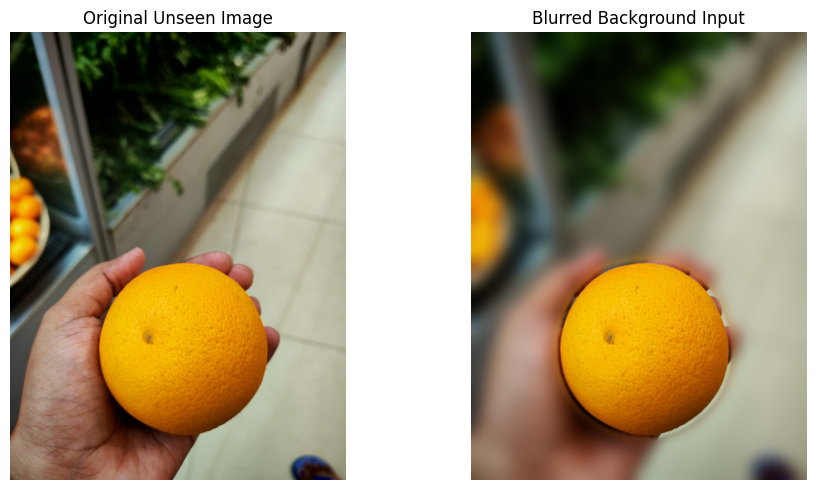

Predicted Class: Orange
Confidence: 97.68%


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageOps
from rembg import remove

# Get uploaded file name
filename = next(iter(uploaded))

# Load unseen image
original = Image.open(filename)
original = ImageOps.exif_transpose(original)
original = original.convert("RGB")

# Create foreground mask
removed = remove(
    original,
    session=rembg_session
).convert("RGBA")

mask = removed.getchannel("A")

if mask.size != original.size:
    mask = mask.resize(
        original.size,
        Image.Resampling.LANCZOS
    )

# Protect fruit edges
mask = mask.filter(ImageFilter.MaxFilter(15))
mask = mask.filter(ImageFilter.GaussianBlur(3))

# Blur background
blurred_background = original.filter(
    ImageFilter.GaussianBlur(20)
)

processed = Image.composite(
    original,
    blurred_background,
    mask
)

# Resize for MobileNetV2
input_image = processed.resize((224, 224))

img_array = np.array(input_image, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Unseen Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed)
plt.title("Blurred Background Input")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")